# 04 · Validation of the simulators (Phase 3, RQ2)
Question: **does data simulated from each fitted model look like the real data?** Cross-validation (Phase 2) measured how
probable the real samples are under each model. Here we check the *features* that matter for the rest of the project:
sparsity, diversity, mean–variance, between-sample dissimilarity and the global picture (PCoA, PERMANOVA).

Design: simulated datasets have the real study design (n = 273 samples, N = 1000 reads, D = 22 categories).
Models: M0 (multinomial), M1 (Dirichlet-multinomial), M3 (logistic-normal, λ = 0.05), and **M4 = M3 + zero inflation**
(added after the first validation round showed that M3 makes too few zeros; section 0). M2 is not used: covariates did not
improve prediction in Phase 2.

Two kinds of uncertainty:
* **parametric bootstrap**: simulate R datasets from a fitted model and compute each statistic → the range of values the model
  produces (its 95 % *band*). If the real value falls outside it, the model does not reproduce that feature.
* **non-parametric bootstrap over samples**: resample the 273 real samples with replacement → a 95 % CI for the real statistic.

**Decision rules (fixed before running):**
1. Among the likelihood-based models (M0, M1, M3) the final simulator is the one with the best held-out log-likelihood (Phase 2)
   unless it reproduces fewer of the summary statistics below (real value inside the 95 % parametric band) than another model.
2. M4 (fixed after round 1, before running round 2) replaces M3 as the **primary** simulator if it reproduces at least as many of the
   7 statistics that are *not* matched by construction (everything except zero share and mean richness) **and** its median
   PERMANOVA R² (real vs simulated) is not larger than M3's, for both distances. Otherwise M3 stays primary.
   Either way M3 and M4 are both used in Phase 4 as a sensitivity analysis.

In [1]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from scipy.spatial.distance import pdist, squareform
from sklearn.model_selection import KFold
from skbio.stats.distance import DistanceMatrix, permanova, permdisp
from skbio.stats.ordination import pcoa
from src.config import SEED, PROCESSED, FIGURES, READS
from src.plotstyle import set_style, PALETTE
from src.eda import shannon, simpson, richness, clr
from src.models import (sample_multinomial, sample_dm, sample_lnm, sample_zilnm, calibrate_zilnm, fit_dm, loglik_dm, fit_lnm, loglik_lnm_is)
warnings.filterwarnings("ignore", category=RuntimeWarning)
set_style(); rng = np.random.default_rng([SEED, 4])

X22 = pd.read_csv(PROCESSED / "counts_top20.csv", index_col=0); X22.index = X22.index.astype(str)
P = np.load(PROCESSED / "model_params.npz", allow_pickle=True)
cols = list(P["columns"]); assert cols == list(X22.columns)
X = X22.values; n, D = X.shape
ui = cols.index("Unassigned"); tax = [j for j in range(D) if j != ui]     # diversity/distances exclude Unassigned (as in 02_eda)
SIM = {"M0": lambda m, r: sample_multinomial(P["p0"], READS, m, r),
       "M1": lambda m, r: sample_dm(P["alpha"], READS, m, r),
       "M3": lambda m, r: sample_lnm(P["mu"], P["Sigma"], READS, m, r)}
COL = {"real": "black", "M0": PALETTE[5], "M1": PALETTE[1], "M3": PALETTE[0]}
print(f"n={n}, D={D}, M3 shrinkage λ={float(P['shrink'])}")

n=273, D=22, M3 shrinkage λ=0.05


## 0. M4: zero-inflated logistic-normal multinomial (calibrated)
Round 1 of this validation showed that M3 produces too few zeros (32 % vs 41 %): in M3 a taxon can only be missing from a sample
by chance in the 1000 reads. M4 adds **structural absence**: taxon j is absent from a sample with probability πⱼ, otherwise it behaves as in M3;
the reads are shared among the present taxa (softmax over present ones). The reference category `Other` is always present.

**Method of moments.** Two numbers per category are matched to the real data, prevalence and mean count, by adjusting two parameters
per category: πⱼ and the ALR mean μⱼ (the covariance Σ is kept from M3). This is a calibration, not a maximum-likelihood fit
(the zero-inflated likelihood sums over 2^(number of zeros) presence patterns), so M4 has no cross-validated log-likelihood.
Because prevalence is matched by construction, the **zero share and mean richness cannot be used to validate M4** (circular);
all the other checks remain independent.

calibration: max relative error prevalence 5.2e-04, mean 4.5e-04


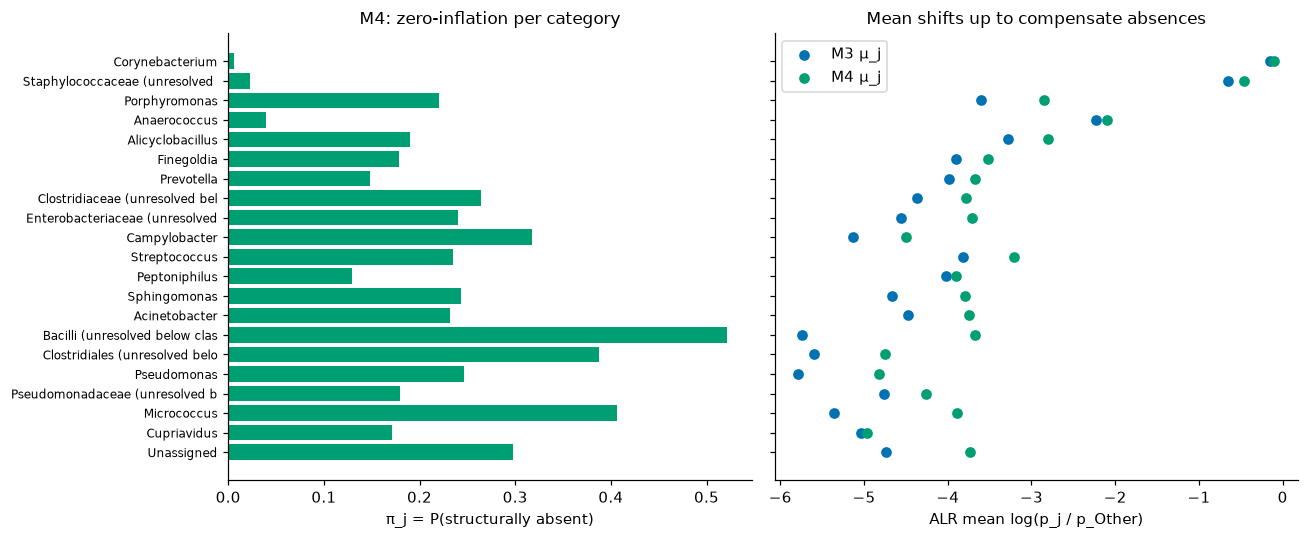

,real prevalence,pi (structural absence),mu M3,mu M4
category,,,,
Corynebacteriaceae;Corynebacterium,0.982,0.006,-0.156,-0.101
Staphylococcaceae (unresolved below family),0.945,0.023,-0.656,-0.456
Porphyromonadaceae;Porphyromonas,0.601,0.221,-3.602,-2.845
Clostridiaceae;Anaerococcus,0.864,0.040,-2.227,-2.102
Alicyclobacillaceae;Alicyclobacillus,0.659,0.190,-3.282,-2.800
Clostridiaceae;Finegoldia,0.615,0.178,-3.900,-3.523
Prevotellaceae;Prevotella,0.619,0.148,-3.991,-3.670
Clostridiaceae (unresolved below family),0.520,0.264,-4.367,-3.783
Enterobacteriaceae (unresolved below family),0.538,0.240,-4.555,-3.713


In [2]:
mu4, pi4, e_prev, e_mean = calibrate_zilnm(X, P["mu"], P["Sigma"], np.random.default_rng([SEED, 41]))
print(f"calibration: max relative error prevalence {e_prev:.1e}, mean {e_mean:.1e}")
SIM["M4"] = lambda m, r: sample_zilnm(mu4, P["Sigma"], pi4, READS, m, r)
COL["M4"] = PALETTE[2]
np.savez(PROCESSED / "model_params_m4.npz", columns=np.array(cols), mu=mu4, Sigma=P["Sigma"], pi=pi4)
cal = pd.DataFrame({"category": cols[:-1], "real prevalence": (X[:, :-1] > 0).mean(0), "pi (structural absence)": pi4,
                    "mu M3": P["mu"], "mu M4": mu4}).set_index("category")
cal.to_csv(PROCESSED / "valid_m4_calibration.csv")
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
y = np.arange(D - 1)[::-1]; short = [c.split(";")[-1][:30] for c in cols[:-1]]
ax[0].barh(y, pi4, color=PALETTE[2]); ax[0].set(xlabel="π_j = P(structurally absent)", title="M4: zero-inflation per category")
ax[0].set_yticks(y); ax[0].set_yticklabels(short, fontsize=8)
ax[1].scatter(P["mu"], y, color=PALETTE[0], label="M3 μ_j"); ax[1].scatter(mu4, y, color=PALETTE[2], label="M4 μ_j")
ax[1].set(xlabel="ALR mean log(p_j / p_Other)", title="Mean shifts up to compensate absences"); ax[1].legend()
fig.tight_layout(); fig.savefig(FIGURES / "valid_m4_calibration.png"); plt.show()
cal.round(3)

## 1. Summary statistics of a dataset

In [3]:
def per_sample(Y):
    T = Y[:, tax]
    return {"shannon": shannon(T), "simpson": simpson(T), "richness": richness(T).astype(float)}

def bc(Y):
    return pdist(Y[:, tax].astype(float), "braycurtis")

def taylor_slope(Y):
    m, v = Y.mean(0), Y.var(0, ddof=1); k = (m > 0) & (v > 0)
    return np.polyfit(np.log10(m[k]), np.log10(v[k]), 1)[0]

def summary_stats(Y, d=None):
    s = per_sample(Y); d = bc(Y) if d is None else d
    return {"zero share": (Y == 0).mean(), "mean richness (of 21)": s["richness"].mean(),
            "mean Shannon": s["shannon"].mean(), "sd Shannon": s["shannon"].std(ddof=1), "mean Simpson": s["simpson"].mean(),
            "median dominant share": np.median(Y[:, tax].max(1) / READS),
            "median Bray-Curtis": np.median(d), "10% Bray-Curtis": np.quantile(d, .1), "Taylor slope": taylor_slope(Y)}

real_stats = summary_stats(X); pd.Series(real_stats).round(3)

zero share                0.407
mean richness (of 21)    12.560
mean Shannon              1.353
sd Shannon                0.543
mean Simpson              0.600
median dominant share     0.493
median Bray-Curtis        0.704
10% Bray-Curtis           0.363
Taylor slope              1.076
dtype: float64

## 2. Parametric bootstrap (R = 200 datasets per model) and non-parametric bootstrap of the real data

In [4]:
R = 200
boot = {}; prev = {}; mom = {}; pool = {}; sims = {}
for m, f in SIM.items():
    rows, pv, mv = [], [], []
    sims[m] = [f(n, rng) for _ in range(R)]
    for Y in sims[m]:
        rows.append(summary_stats(Y)); pv.append((Y > 0).mean(0)); mv.append(np.c_[Y.mean(0), Y.var(0, ddof=1)])
    boot[m] = pd.DataFrame(rows); prev[m] = np.array(pv); mom[m] = np.array(mv)

# non-parametric bootstrap of the real data; Bray-Curtis only over pairs of DIFFERENT original samples (duplicates give 0)
Dreal = squareform(bc(X)); rows = []
iu = np.triu_indices(n, 1)
for _ in range(R):
    i = rng.integers(0, n, n)
    d = Dreal[np.ix_(i, i)][iu][(i[iu[0]] != i[iu[1]])]
    rows.append(summary_stats(X[i], d))
real_boot = pd.DataFrame(rows)

tab = []
for s in real_stats:
    lo, hi = real_boot[s].quantile([.025, .975])
    row = {"statistic": s, "real": real_stats[s], "real 95% CI": f"{lo:.3f}–{hi:.3f}"}
    for m in SIM:
        blo, bhi = boot[m][s].quantile([.025, .975])
        row[f"{m} band"] = f"{blo:.3f}–{bhi:.3f}"; row[f"{m} ok"] = blo <= real_stats[s] <= bhi
    tab.append(row)
stat_tab = pd.DataFrame(tab).set_index("statistic"); stat_tab.to_csv(PROCESSED / "valid_summary_stats.csv")
CIRCULAR = ["zero share", "mean richness (of 21)"]          # matched by construction for M4
indep = [s for s in stat_tab.index if s not in CIRCULAR]
print("statistics reproduced (real value inside the model's 95% parametric band):",
      {m: int(stat_tab[f"{m} ok"].sum()) for m in SIM}, "of", len(stat_tab))
print("of the 7 statistics NOT matched by construction for M4:", {m: int(stat_tab.loc[indep, f"{m} ok"].sum()) for m in SIM})
stat_tab

statistics reproduced (real value inside the model's 95% parametric band): {'M0': 0, 'M1': 0, 'M3': 4, 'M4': 6} of 9
of the 7 statistics NOT matched by construction for M4: {'M0': 0, 'M1': 0, 'M3': 4, 'M4': 4}


,real,real 95% CI,M0 band,M0 ok,M1 band,M1 ok,M3 band,M3 ok,M4 band,M4 ok
statistic,,,,,,,,,,
zero share,0.406760,0.382–0.433,0.000–0.000,False,0.422–0.445,False,0.302–0.340,False,0.393–0.423,True
mean richness (of 21),12.560440,12.032–13.038,20.996–21.000,False,11.769–12.246,False,13.952–14.747,False,12.220–12.824,True
mean Shannon,1.353258,1.296–1.422,2.332–2.340,False,1.663–1.729,False,1.340–1.446,True,1.335–1.428,True
sd Shannon,0.542699,0.496–0.590,0.033–0.039,False,0.257–0.308,False,0.428–0.497,False,0.418–0.496,False
mean Simpson,0.599521,0.577–0.625,0.854–0.855,False,0.733–0.753,False,0.586–0.632,True,0.592–0.635,True
median dominant share,0.493000,0.435–0.516,0.228–0.232,False,0.346–0.377,False,0.468–0.534,True,0.458–0.517,True
median Bray-Curtis,0.703834,0.674–0.730,0.064–0.066,False,0.666–0.699,False,0.645–0.693,False,0.677–0.726,True
10% Bray-Curtis,0.363000,0.341–0.384,0.048–0.050,False,0.461–0.493,False,0.340–0.378,True,0.373–0.417,False
Taylor slope,1.076091,1.026–1.425,0.890–0.965,False,0.909–1.073,False,1.237–1.459,False,1.158–1.351,False


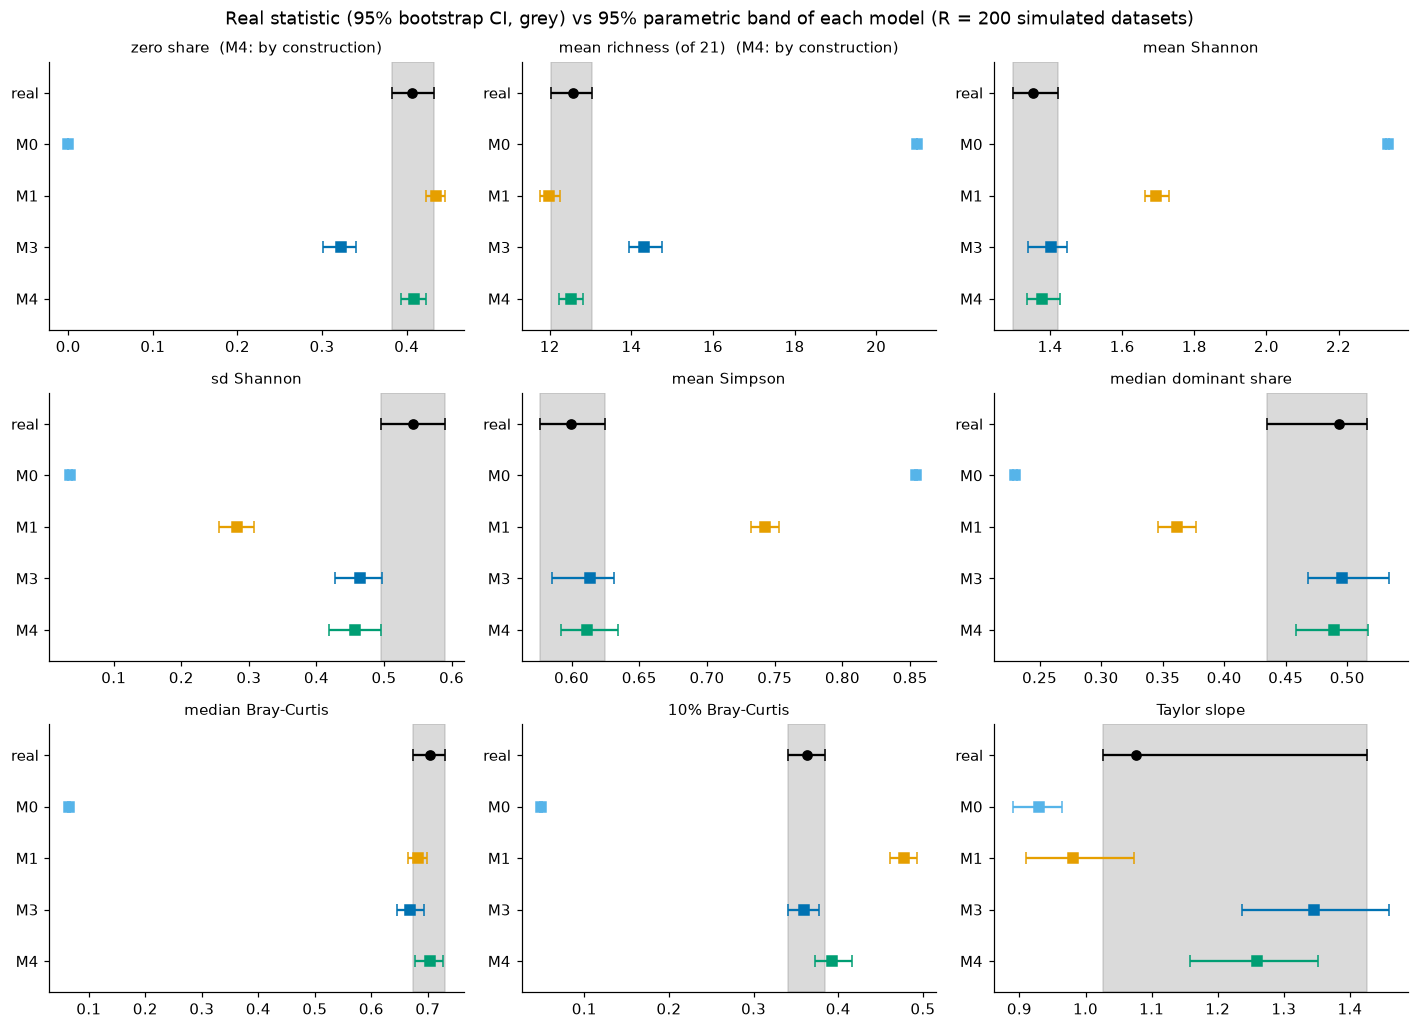

In [5]:
# figure: each statistic, real value + CI (black) vs the band of each model
S = list(real_stats); fig, axes = plt.subplots(3, 3, figsize=(13, 9.5)); axes = axes.ravel()
for a, s in zip(axes, S):
    lo, hi = real_boot[s].quantile([.025, .975])
    a.errorbar([real_stats[s]], [3], xerr=[[real_stats[s] - lo], [hi - real_stats[s]]], fmt="o", color="k", capsize=4)
    for k, m in enumerate(SIM):
        q = boot[m][s].quantile([.025, .5, .975])
        a.errorbar([q[.5]], [2 - k], xerr=[[q[.5] - q[.025]], [q[.975] - q[.5]]], fmt="s", color=COL[m], capsize=4)
        a.axvspan(lo, hi, color="grey", alpha=.08)
    a.set_yticks([3, 2, 1, 0, -1]); a.set_yticklabels(["real"] + list(SIM)); a.set_title(s + ("  (M4: by construction)" if s in CIRCULAR else ""), fontsize=10); a.set_ylim(-1.6, 3.6)
fig.suptitle("Real statistic (95% bootstrap CI, grey) vs 95% parametric band of each model (R = 200 simulated datasets)")
fig.tight_layout(); fig.savefig(FIGURES / "valid_summary_stats.png"); plt.show()

## 3. Distributions: alpha diversity and Bray–Curtis (KS and Wasserstein, calibrated by the parametric bootstrap)

For each model, a large reference pool is built from 20 simulated datasets. Then:
* **KS test** (per-sample metrics only, whose values are independent): two-sample Kolmogorov–Smirnov statistic and p-value, real vs pool.
* **Wasserstein distance** W (the "earth mover's distance": the average shift needed to turn one distribution into the other, in the units of the metric).
  It is calibrated by the parametric bootstrap: W between 100 *other* simulated datasets and the pool shows how large W is when the model is true.
  Monte Carlo p = (1 + #{W_null ≥ W_real}) / (1 + 100). This also works for Bray–Curtis, whose pairwise values are not independent (so no KS p-value there).

In [6]:
def metric_values(Y, which):
    return bc(Y) if which == "Bray-Curtis" else per_sample(Y)[which]
rows = []
for m in SIM:
    for which in ["shannon", "richness", "simpson", "Bray-Curtis"]:
        npool = 5 if which == "Bray-Curtis" else 20
        ref = np.concatenate([metric_values(Y, which) for Y in sims[m][:npool]])
        v_real = metric_values(X, which); W_real = stats.wasserstein_distance(v_real, ref)
        W_null = np.array([stats.wasserstein_distance(metric_values(Y, which), ref) for Y in sims[m][100:200]])
        row = {"model": m, "metric": which, "W real": W_real, "W null 95%": np.quantile(W_null, .95),
               "MC p (W)": (1 + (W_null >= W_real).sum()) / (1 + len(W_null))}
        if which != "Bray-Curtis":
            ks = stats.ks_2samp(v_real, ref); row.update({"KS D": ks.statistic, "KS p": ks.pvalue})
        rows.append(row)
dist_tab = pd.DataFrame(rows); dist_tab.to_csv(PROCESSED / "valid_distributions.csv", index=False); dist_tab.round(4)

,model,metric,W real,W null 95%,MC p (W),KS D,KS p
0,M0,shannon,0.9825,0.0044,0.0099,0.9958,0.0000
1,M0,richness,8.4394,0.0035,0.0099,0.9888,0.0000
2,M0,simpson,0.2548,0.0008,0.0099,0.9588,0.0000
3,M0,Bray-Curtis,0.6067,0.0015,0.0099,NaN,NaN
4,M1,shannon,0.3465,0.0379,0.0099,0.3189,0.0000
5,M1,richness,1.7368,0.2664,0.0099,0.2412,0.0000
6,M1,simpson,0.1456,0.0126,0.0099,0.3484,0.0000
7,M1,Bray-Curtis,0.0638,0.0135,0.0099,NaN,NaN
8,M3,shannon,0.0727,0.0640,0.0198,0.0760,0.0946
9,M3,richness,1.8196,0.4253,0.0099,0.2513,0.0000


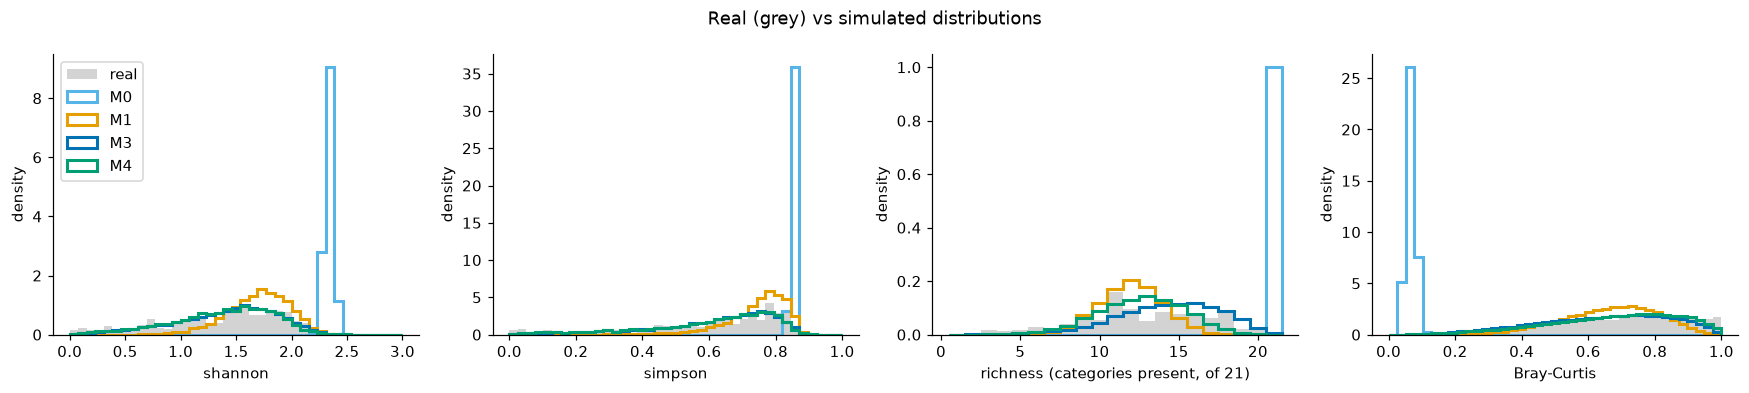

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for a, which, bins in zip(ax, ["shannon", "simpson", "richness", "Bray-Curtis"],
                          [np.linspace(0, 3, 40), np.linspace(0, 1, 40), np.arange(0.5, 22.5, 1), np.linspace(0, 1, 40)]):
    a.hist(metric_values(X, which), bins=bins, density=True, color="lightgrey", label="real")
    for m in SIM:
        npool = 5 if which == "Bray-Curtis" else 20
        a.hist(np.concatenate([metric_values(Y, which) for Y in sims[m][:npool]]), bins=bins, density=True, histtype="step", lw=2, color=COL[m], label=m)
    a.set(xlabel=which if which != "richness" else "richness (categories present, of 21)", ylabel="density")
ax[0].legend(); fig.suptitle("Real (grey) vs simulated distributions"); fig.tight_layout()
fig.savefig(FIGURES / "valid_distributions.png"); plt.show()

## 4. Per-category prevalence and mean–variance

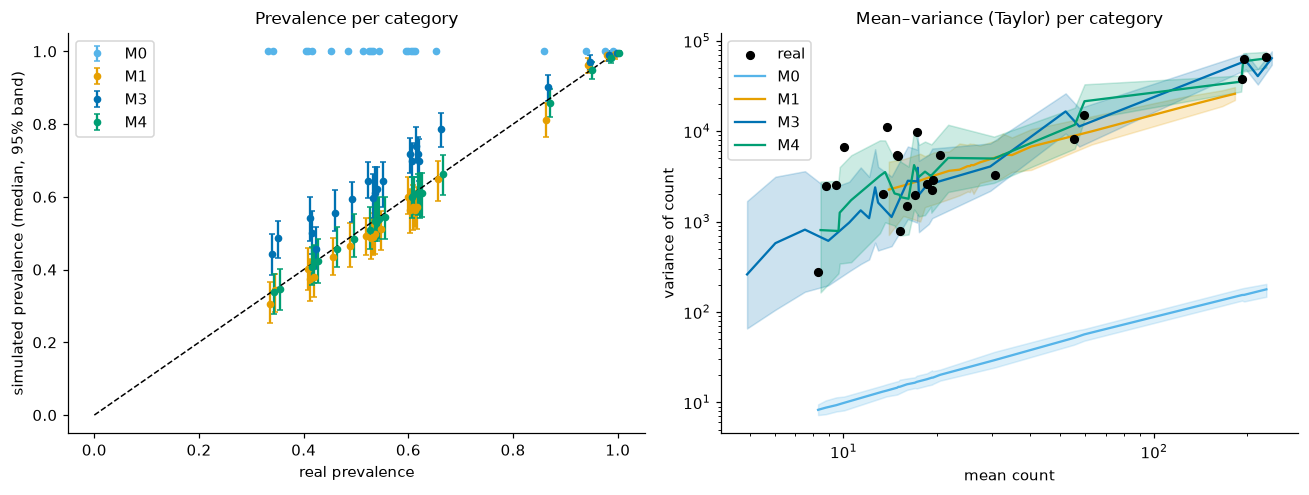

share of the 22 categories whose real VARIANCE lies in the model's 95% band: {'M0': 0.0, 'M1': 0.4090909090909091, 'M3': 0.6363636363636364, 'M4': 0.7727272727272727}
share of the 22 categories whose real PREVALENCE lies in the model's 95% band: {'M0': 0.0, 'M1': 0.9545454545454546, 'M3': 0.18181818181818182, 'M4': 1.0}


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
rp = (X > 0).mean(0)
for k, m in enumerate(SIM):
    q = np.quantile(prev[m], [.025, .5, .975], axis=0)
    ax[0].errorbar(rp + (k - 1.5) * 0.004, q[1], yerr=[q[1] - q[0], q[2] - q[1]], fmt="o", ms=4, color=COL[m], label=m, capsize=2)
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set(xlabel="real prevalence", ylabel="simulated prevalence (median, 95% band)", title="Prevalence per category"); ax[0].legend()
rm, rv = X.mean(0), X.var(0, ddof=1)
ax[1].scatter(rm, rv, color="k", s=25, zorder=4, label="real")
for m in SIM:
    q = np.quantile(mom[m][:, :, 1], [.025, .5, .975], axis=0); mm = mom[m][:, :, 0].mean(0); o = np.argsort(mm)
    ax[1].fill_between(mm[o], q[0][o], q[2][o], color=COL[m], alpha=.2); ax[1].plot(mm[o], q[1][o], color=COL[m], label=m)
ax[1].set(xscale="log", yscale="log", xlabel="mean count", ylabel="variance of count", title="Mean–variance (Taylor) per category"); ax[1].legend()
fig.tight_layout(); fig.savefig(FIGURES / "valid_prevalence_meanvar.png"); plt.show()
cover = {m: float(((np.quantile(mom[m][:, :, 1], .025, 0) <= rv) & (rv <= np.quantile(mom[m][:, :, 1], .975, 0))).mean()) for m in SIM}
cover_p = {m: float(((np.quantile(prev[m], .025, 0) <= rp) & (rp <= np.quantile(prev[m], .975, 0))).mean()) for m in SIM}
print("share of the 22 categories whose real VARIANCE lies in the model's 95% band:", cover)
print("share of the 22 categories whose real PREVALENCE lies in the model's 95% band:", cover_p)

## 5. Can real and simulated samples be told apart? PCoA overlay and PERMANOVA
Real (273) and one simulated dataset (273) are pooled; PERMANOVA tests "source" (real vs simulated). A perfect simulator gives
R² ≈ 0 and p ≈ uniform. With 546 samples PERMANOVA detects even small differences, so **R² (effect size) matters more than p**.
PERMANOVA reacts to differences in centroid *and* spread, so PERMDISP (test of equal dispersion) is reported alongside.
Repeated over 20 simulated datasets to show the variability.

In [9]:
def dms(Y):
    T = Y[:, tax].astype(float); ids = [str(i) for i in range(len(Y))]
    return {"Bray-Curtis": DistanceMatrix(squareform(pdist(T, "braycurtis")), ids),
            "Aitchison": DistanceMatrix(squareform(pdist(clr(T, 0.5), "euclidean")), ids)}
grp = pd.DataFrame({"source": ["real"] * n + ["sim"] * n}, index=[str(i) for i in range(2 * n)])
rows = []
for m in SIM:
    for r in range(20):
        Y = np.r_[X, sims[m][r]]
        for k, dm in dms(Y).items():
            res = permanova(dm, grp, column="source", permutations=999, seed=SEED + r)
            F = float(res["test statistic"]); row = {"model": m, "rep": r, "distance": k, "pseudo-F": F, "R2": F / (F + 2 * n - 2), "p": float(res["p-value"])}
            if r == 0: row["PERMDISP p"] = float(permdisp(dm, grp, column="source", permutations=999, seed=SEED)["p-value"])
            rows.append(row)
perm = pd.DataFrame(rows); perm.to_csv(PROCESSED / "valid_permanova.csv", index=False)
perm_sum = perm.groupby(["model", "distance"]).agg(R2_median=("R2", "median"), R2_q10=("R2", lambda x: x.quantile(.1)), R2_q90=("R2", lambda x: x.quantile(.9)),
                                                    share_p_lt_005=("p", lambda x: (x < .05).mean()), permdisp_p=("PERMDISP p", "first"))
perm_sum.round(4)

R2_median  R2_q10  R2_q90  share_p_lt_005  permdisp_p
model distance                                                          
M0    Aitchison       0.0390  0.0386  0.0395            1.00       0.001
      Bray-Curtis     0.1091  0.1088  0.1094            1.00       0.001
M1    Aitchison       0.0021  0.0015  0.0028            0.00       0.092
      Bray-Curtis     0.0136  0.0121  0.0150            1.00       0.001
M3    Aitchison       0.0008  0.0006  0.0015            0.00       0.014
      Bray-Curtis     0.0018  0.0014  0.0022            0.05       0.012
M4    Aitchison       0.0020  0.0017  0.0025            0.00       0.807
      Bray-Curtis     0.0010  0.0005  0.0019            0.00       0.159

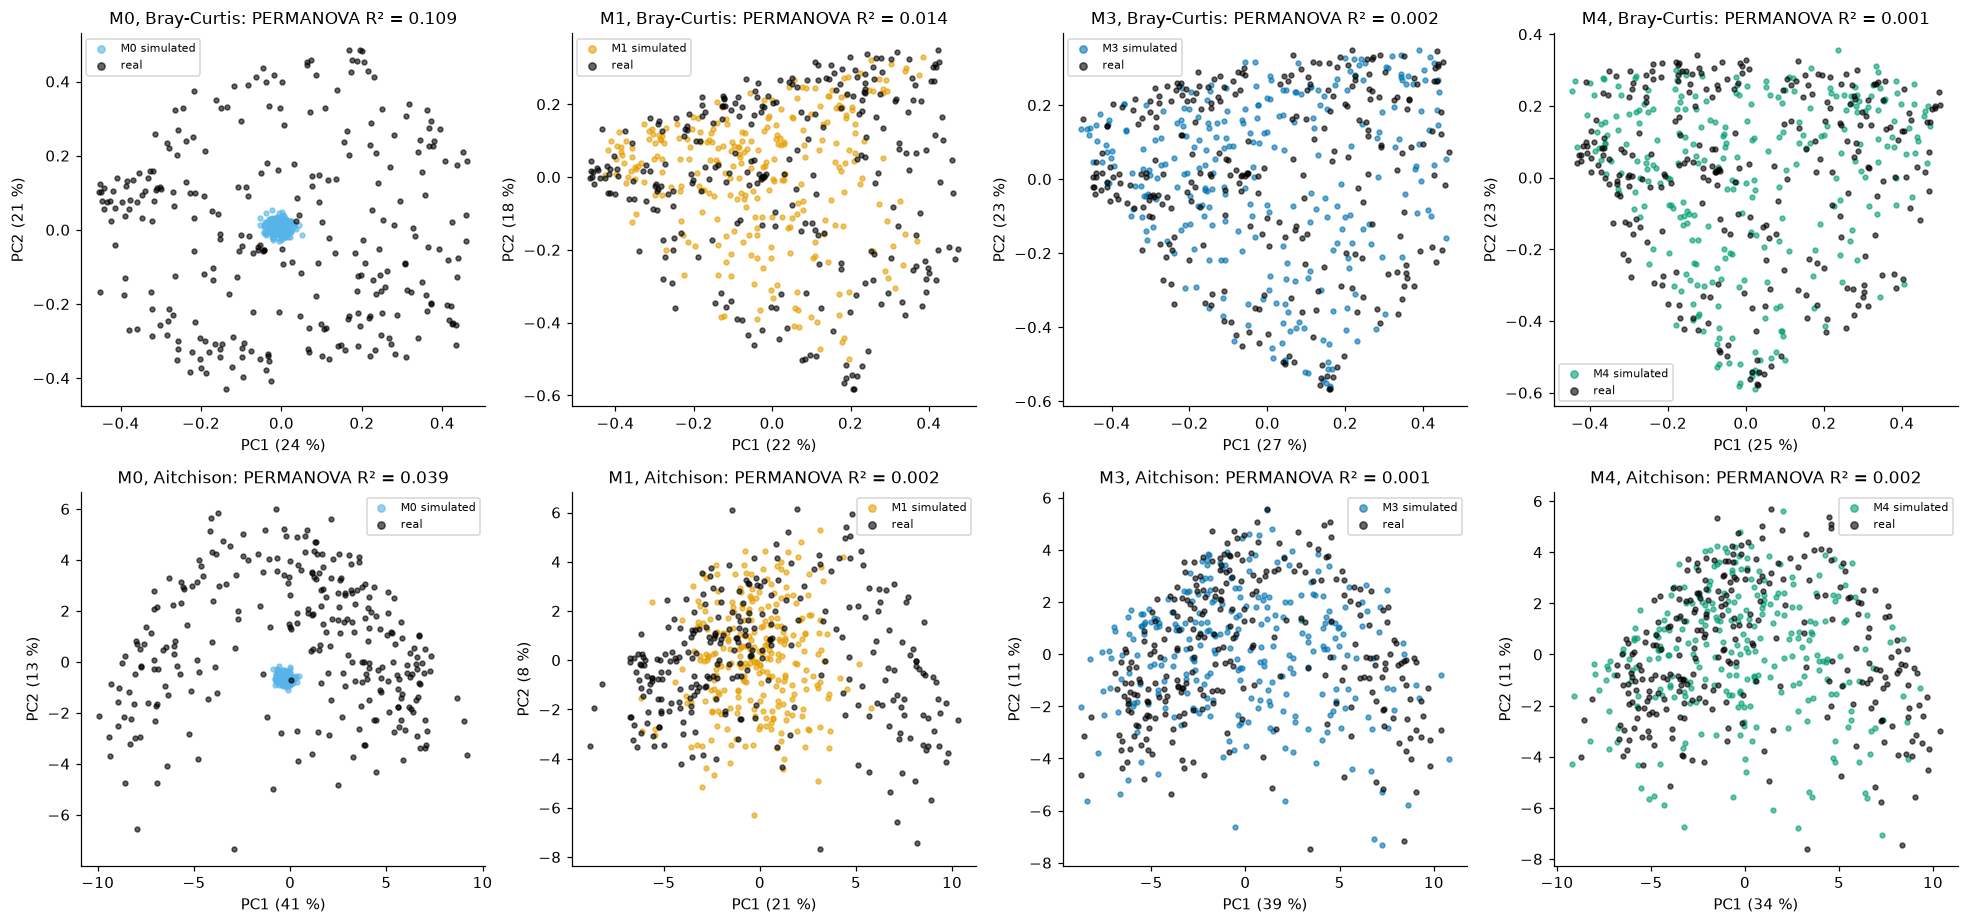

In [10]:
fig, ax = plt.subplots(2, 4, figsize=(18, 8.5))
for c, m in enumerate(SIM):
    Y = np.r_[X, sims[m][0]]
    for r_, (k, dm) in enumerate(dms(Y).items()):
        o = pcoa(dm, number_of_dimensions=2); Pc = o.samples.values; ev = o.proportion_explained.values
        ax[r_, c].scatter(Pc[n:, 0], Pc[n:, 1], s=10, color=COL[m], alpha=.6, label=f"{m} simulated")
        ax[r_, c].scatter(Pc[:n, 0], Pc[:n, 1], s=10, color="k", alpha=.6, label="real")
        R2m = perm_sum.loc[(m, k), "R2_median"]
        ax[r_, c].set(title=f"{m}, {k}: PERMANOVA R² = {R2m:.3f}", xlabel=f"PC1 ({100*ev[0]:.0f} %)", ylabel=f"PC2 ({100*ev[1]:.0f} %)")
        ax[r_, c].legend(fontsize=7, markerscale=1.5)
fig.tight_layout(); fig.savefig(FIGURES / "valid_pcoa_overlay.png"); plt.show()

## 6. Sensitivity: remove the 7 samples with < 80 % assigned reads
These samples carry a large `Unassigned` category (missing mass from the source table). Does the model comparison change without them?

In [11]:
meta = pd.read_csv(PROCESSED / "metadata.csv", index_col=0); meta.index = meta.index.astype(str)
keep = meta.loc[X22.index, "assigned_reads"].values >= 0.8 * READS
Xs = X[keep].astype(float); ns = len(Xs)
cv1, cv3 = np.full(ns, np.nan), np.full(ns, np.nan)
for tr, te in KFold(5, shuffle=True, random_state=SEED).split(Xs):
    cv1[te] = loglik_dm(Xs[te], fit_dm(Xs[tr]))
    mu, S, _ = fit_lnm(Xs[tr], shrink=float(P["shrink"]))
    cv3[te] = [loglik_lnm_is(x, mu, S, 10000, rng)[0] for x in Xs[te]]
d = cv3 - cv1; a_s = fit_dm(Xs)
sens = pd.Series({"n": ns, "M1 rho (full data)": 1 / (1 + P["alpha"].sum()), "M1 rho (subset)": 1 / (1 + a_s.sum()),
                  "CV M3 − M1 (subset)": d.mean(), "SE": d.std(ddof=1) / np.sqrt(ns), "share M3 better": (d > 0).mean()})
sens.to_csv(PROCESSED / "valid_sensitivity_low_assigned.csv", header=["value"]); sens.round(4)

n                      266.0000
M1 rho (full data)       0.1718
M1 rho (subset)          0.1725
CV M3 − M1 (subset)      7.0597
SE                       0.3245
share M3 better          0.9060
dtype: float64

## 7. Final model

In [12]:
# rule 1: likelihood-based models
ok = {m: int(stat_tab[f"{m} ok"].sum()) for m in ["M0", "M1", "M3"]}
cv = pd.read_csv(PROCESSED / "model_comparison.csv", index_col=0)["CV logL per sample"]
best_cv = "M3" if cv.filter(like="M3").max() > cv["M1"] else "M1"
rule1 = best_cv if ok[best_cv] >= max(ok.values()) else max(ok, key=ok.get)
# rule 2: M4 vs M3
ok_ind = {m: int(stat_tab.loc[indep, f"{m} ok"].sum()) for m in ["M3", "M4"]}
r2 = perm_sum["R2_median"]
m4_wins = ok_ind["M4"] >= ok_ind["M3"] and all(r2[("M4", k)] <= r2[("M3", k)] for k in ["Bray-Curtis", "Aitchison"])
final = "M4" if (rule1 == "M3" and m4_wins) else rule1
print("rule 1 (likelihood models):", ok, "best CV:", best_cv, "->", rule1)
print("rule 2: independent statistics reproduced", ok_ind, "| median R2", {k: (round(r2[('M3', k)], 4), round(r2[('M4', k)], 4)) for k in ['Bray-Curtis', 'Aitchison']}, "-> M4 wins:", m4_wins)
print("PRIMARY simulator for Phase 4:", final, "(the other of M3/M4 is used as sensitivity analysis)")
pd.Series({"primary_model": final, "rule1": rule1, "m4_wins": m4_wins, **{f"stats_indep_ok_{m}": v for m, v in ok_ind.items()}}).to_csv(PROCESSED / "valid_final_model.csv", header=["value"])

rule 1 (likelihood models): {'M0': 0, 'M1': 0, 'M3': 4} best CV: M3 -> M3
rule 2: independent statistics reproduced {'M3': 4, 'M4': 4} | median R2 {'Bray-Curtis': (np.float64(0.0018), np.float64(0.001)), 'Aitchison': (np.float64(0.0008), np.float64(0.002))} -> M4 wins: False
PRIMARY simulator for Phase 4: M3 (the other of M3/M4 is used as sensitivity analysis)
